# LIME — Qualitative Analysis

Explains individual predictions of the fine-tuned XLM-RoBERTa model using LIME.
For each of the 5 rating classes we sample a mix of correctly and incorrectly classified reviews,
then visualise which words pushed the model toward/away from each class.

In [7]:
!pip install lime transformers sentencepiece -q

In [8]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from lime.lime_text import LimeTextExplainer
from tqdm import tqdm
import re
import warnings
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


## Config

In [9]:
MODEL_NAME  = 'xlm-roberta-large'
CKPT_PATH   = '/kaggle/input/models/vladcvx/cil-roberta-5-epochs/pytorch/default/1/best_model_num_epochs-5lr-1e-06warmup_ratio-0.1train_size-226800val_size-25200time-20260521-100628.pth'
DATA_DIR    = '/kaggle/input/datasets/vladcvx/sentiment-classification-data-256-roberta/data1'
PLOTS_DIR   = '/kaggle/working/lime_plots'
os.makedirs(PLOTS_DIR, exist_ok=True)

LABEL_NAMES     = ['1 star', '2 stars', '3 stars', '4 stars', '5 stars']
SAMPLES_PER_CLASS = 5   # correct + incorrect each → 10 total per class
MAX_LENGTH      = 256
LIME_NUM_FEATURES = 15
LIME_NUM_SAMPLES  = 200   # perturbations per explanation; increase for more stable results
VAL_SIZE        = 0.10

## Load Data & Preprocessing

In [10]:
def split_title_body(text: str):
    parts = text.split('\n\n', 1)
    if len(parts) == 2:
        return parts[0].strip(), parts[1].strip()
    return text.strip(), ''

def preprocess(text: str):
    title, body = split_title_body(text)
    title = re.sub(r'\s+', ' ', title).strip()
    body  = re.sub(r'\s+', ' ', body).strip()
    # Reconstruct as flat string for LIME (which perturbs words in a single string)
    return title + ' </s> ' + body if body else title

train_df = pd.read_csv(f'{DATA_DIR}/train.csv')
test_df  = pd.read_csv(f'{DATA_DIR}/test.csv')

_, val_df = train_test_split(
    train_df,
    test_size=VAL_SIZE,
    random_state=SEED,
    stratify=train_df['label'],
)
val_df = val_df.reset_index(drop=True)
val_df['text_clean'] = val_df['sentence'].apply(preprocess)

print(f'Val set: {len(val_df):,} rows')
print(val_df['label'].value_counts().sort_index())

Val set: 25,200 rows
label
0    5040
1    5040
2    5040
3    5040
4    5040
Name: count, dtype: int64


## Load Model

In [11]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=5)
model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
model = model.to(device)
model.eval()
print('Model loaded.')

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-large
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded.


## Predict on Validation Set

We run inference on the full val set first so we can sample
a mix of correct and incorrect predictions per class.

In [12]:
def predict_proba_batch(texts, batch_size=32):
    """Returns softmax probabilities (N, 5) for a list of texts."""
    all_probs = []
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i+batch_size]
        enc = tokenizer(
            batch_texts,
            truncation=True, padding=True,
            max_length=MAX_LENGTH, return_tensors='pt'
        )
        enc = {k: v.to(device) for k, v in enc.items()}
        with torch.no_grad():
            logits = model(**enc).logits
        probs = F.softmax(logits, dim=1).cpu().numpy()
        all_probs.append(probs)
    return np.vstack(all_probs)

print('Running inference on val set...')
val_probs = predict_proba_batch(val_df['text_clean'].tolist())
val_preds = val_probs.argmax(axis=1)

val_df['pred']    = val_preds
val_df['correct'] = (val_preds == val_df['label'].values)

mae = np.mean(np.abs(val_preds - val_df['label'].values))
print(f'Val score: {1 - mae/4:.4f}')
print(f'Correct  : {val_df["correct"].sum():,} / {len(val_df):,}')

Running inference on val set...
Val score: 0.9081
Correct  : 16,827 / 25,200


## Sample Examples per Class

`SAMPLES_PER_CLASS` correct + `SAMPLES_PER_CLASS` incorrect per class.

In [13]:
def sample_per_class(df, n_correct, n_incorrect, seed=SEED):
    samples = []
    for label in range(5):
        cls_df = df[df['label'] == label]
        correct   = cls_df[cls_df['correct']].sample(
            min(n_correct,   len(cls_df[cls_df['correct']])),   random_state=seed)
        incorrect = cls_df[~cls_df['correct']].sample(
            min(n_incorrect, len(cls_df[~cls_df['correct']])),  random_state=seed)
        for _, row in correct.iterrows():
            samples.append({**row.to_dict(), 'split': 'correct'})
        for _, row in incorrect.iterrows():
            samples.append({**row.to_dict(), 'split': 'incorrect'})
    return samples

samples = sample_per_class(val_df, n_correct=SAMPLES_PER_CLASS, n_incorrect=SAMPLES_PER_CLASS)
print(f'Total samples to explain: {len(samples)}')
for label in range(5):
    cls = [s for s in samples if s['label'] == label]
    print(f'  {LABEL_NAMES[label]}: {sum(1 for s in cls if s["split"]=="correct")} correct, '
          f'{sum(1 for s in cls if s["split"]=="incorrect")} incorrect')

Total samples to explain: 50
  1 star: 5 correct, 5 incorrect
  2 stars: 5 correct, 5 incorrect
  3 stars: 5 correct, 5 incorrect
  4 stars: 5 correct, 5 incorrect
  5 stars: 5 correct, 5 incorrect


## Run LIME Explanations

In [14]:
def predict_proba_lime(texts):
    """LIME-compatible predict function: takes list of strings, returns (N, 5) probs."""
    return predict_proba_batch(texts, batch_size=32)

explainer = LimeTextExplainer(
    class_names=LABEL_NAMES,
    bow=False,   # preserve word order context
)

explanations = []
for s in tqdm(samples, desc='LIME'):
    text       = s['text_clean']
    true_label = s['label']
    pred_label = s['pred']

    exp = explainer.explain_instance(
        text,
        predict_proba_lime,
        num_features=LIME_NUM_FEATURES,
        num_samples=LIME_NUM_SAMPLES,
        labels=(true_label, pred_label) if true_label != pred_label else (true_label,),
    )
    explanations.append({
        'text'      : s['sentence'],
        'text_clean': text,
        'true_label': true_label,
        'pred_label': pred_label,
        'correct'   : s['split'] == 'correct',
        'exp'       : exp,
        'conf'      : float(predict_proba_lime([text])[0][pred_label]),
    })

print(f'Done — {len(explanations)} explanations computed.')

LIME: 100%|██████████| 50/50 [05:31<00:00,  6.63s/it]

Done — 50 explanations computed.


## Visualise

For each class, show one correct and one incorrect prediction side by side.
Positive weights (green) push toward the predicted class; negative (red) push away.

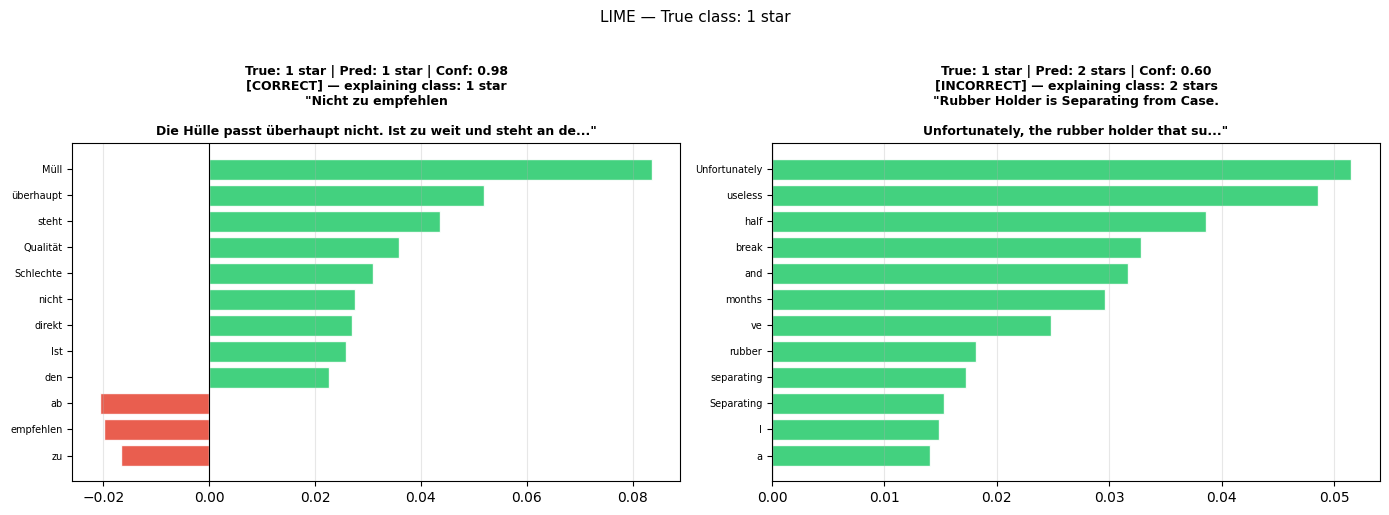

Saved: /kaggle/working/lime_plots/lime_class0_1_star.png


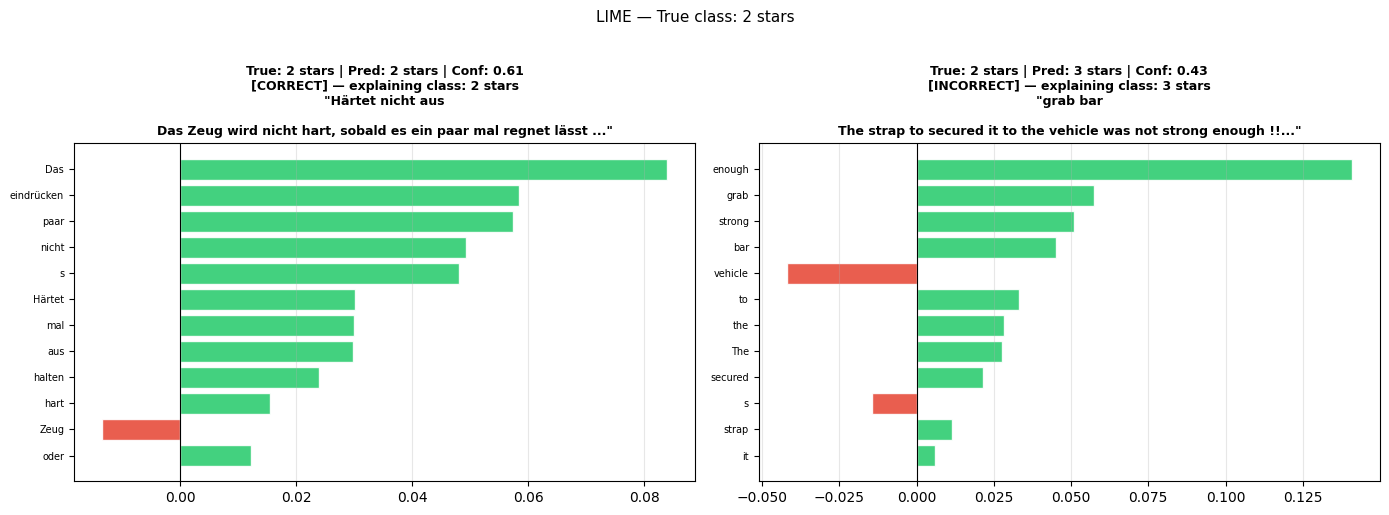

Saved: /kaggle/working/lime_plots/lime_class1_2_stars.png


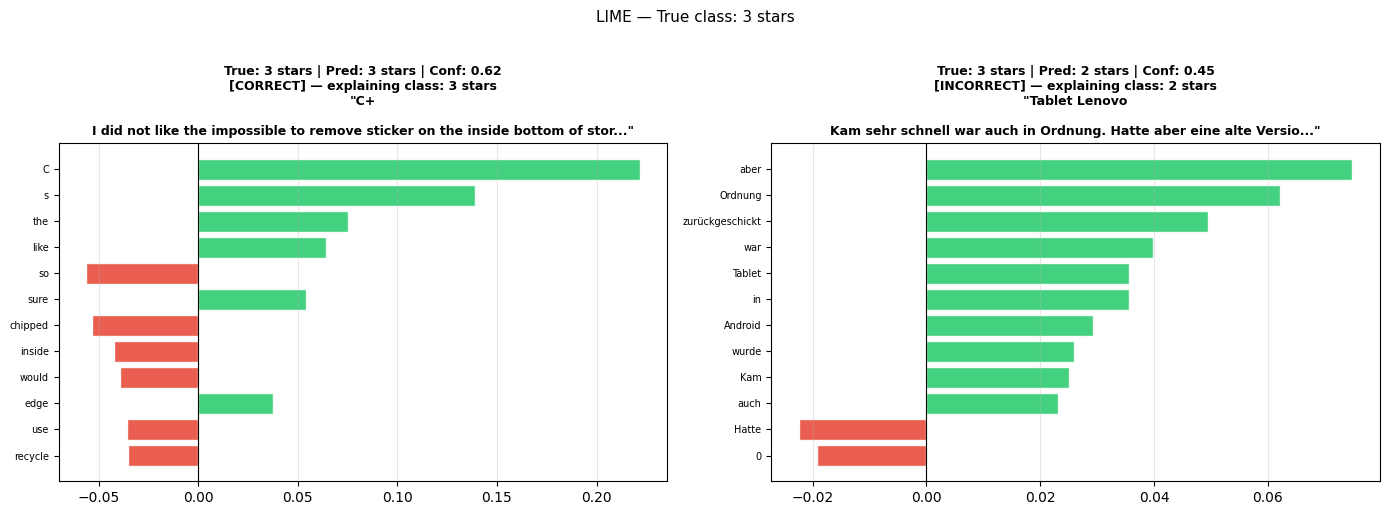

Saved: /kaggle/working/lime_plots/lime_class2_3_stars.png


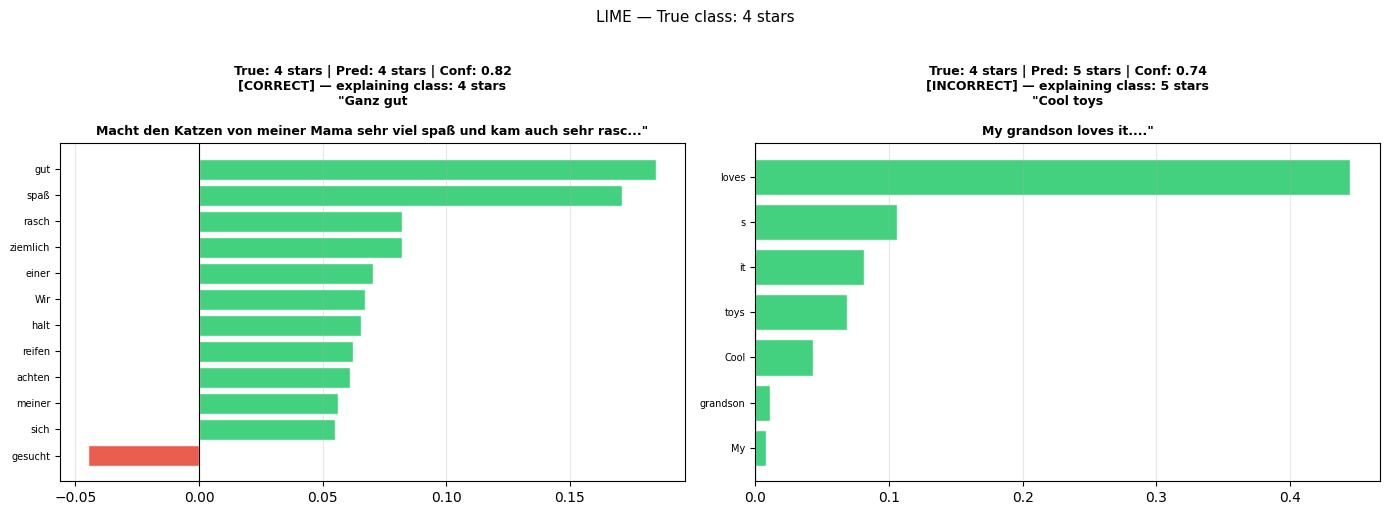

Saved: /kaggle/working/lime_plots/lime_class3_4_stars.png


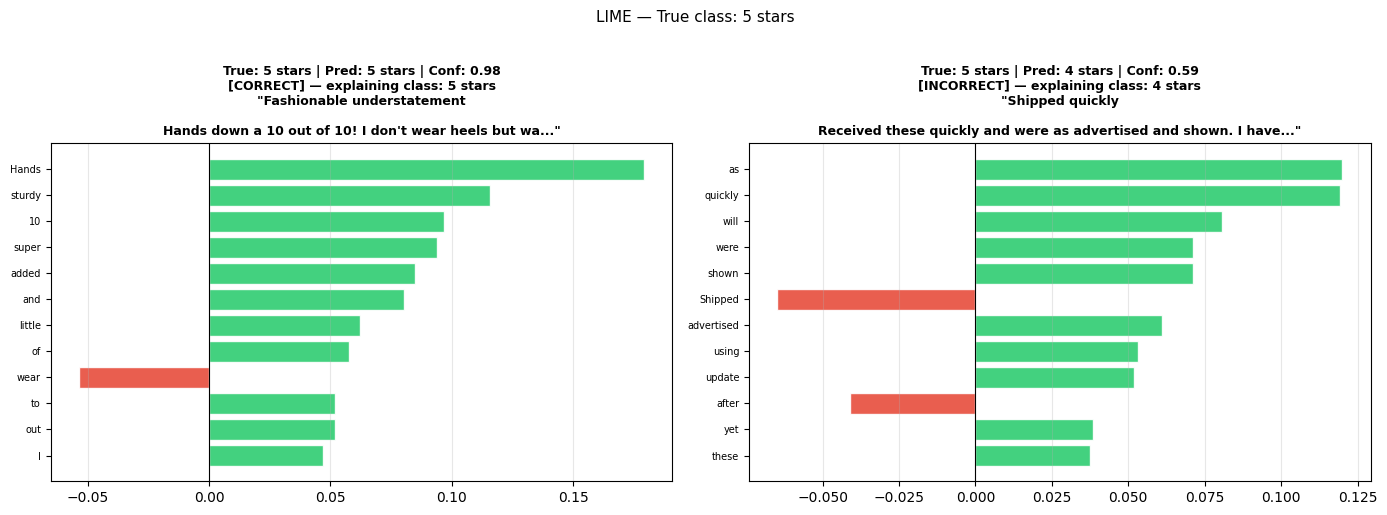

Saved: /kaggle/working/lime_plots/lime_class4_5_stars.png


In [15]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def plot_lime_explanation(exp, label_idx, title, ax, n_features=12):
    """Bar chart of LIME feature weights for a given label."""
    weights = dict(exp.as_list(label=label_idx))
    # sort by absolute weight
    sorted_w = sorted(weights.items(), key=lambda x: abs(x[1]), reverse=True)[:n_features]
    words  = [w for w, _ in sorted_w][::-1]
    values = [v for _, v in sorted_w][::-1]
    colors = ['#2ecc71' if v > 0 else '#e74c3c' for v in values]
    ax.barh(words, values, color=colors, edgecolor='white', alpha=0.9)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(title, fontsize=9, fontweight='bold')
    ax.tick_params(axis='y', labelsize=7)
    ax.grid(axis='x', alpha=0.3)

for label in range(5):
    cls_exps = [e for e in explanations if e['true_label'] == label]
    correct_exps   = [e for e in cls_exps if e['correct']]
    incorrect_exps = [e for e in cls_exps if not e['correct']]

    to_show = []
    if correct_exps:
        to_show.append(('correct',   correct_exps[0]))
    if incorrect_exps:
        to_show.append(('incorrect', incorrect_exps[0]))
    if not to_show:
        continue

    fig, axes = plt.subplots(1, len(to_show), figsize=(7 * len(to_show), 5))
    if len(to_show) == 1:
        axes = [axes]

    for ax, (split, e) in zip(axes, to_show):
        label_to_explain = e['true_label'] if split == 'correct' else e['pred_label']
        title = (
            f'True: {LABEL_NAMES[e["true_label"]]} | '
            f'Pred: {LABEL_NAMES[e["pred_label"]]} | '
            f'Conf: {e["conf"]:.2f}\n'
            f'[{split.upper()}] — explaining class: {LABEL_NAMES[label_to_explain]}\n'
            f'"{e["text"][:80]}..."'
        )
        try:
            plot_lime_explanation(e['exp'], label_to_explain, title, ax)
        except Exception as ex:
            ax.set_title(f'Could not plot: {ex}', fontsize=8)

    plt.suptitle(f'LIME — True class: {LABEL_NAMES[label]}', fontsize=11, y=1.02)
    plt.tight_layout()
    fname = f'{PLOTS_DIR}/lime_class{label}_{LABEL_NAMES[label].replace(" ","_")}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {fname}')

## HTML Export (optional)

LIME's built-in HTML renderer — useful for interactive inspection in the notebook.

In [17]:
from IPython.display import display, HTML

print('=== Interactive LIME explanations (first 3 samples) ===')
for e in explanations[:3]:
    label_to_explain = e['pred_label']
    print(f'\nTrue: {LABEL_NAMES[e["true_label"]]} | Pred: {LABEL_NAMES[e["pred_label"]]} | {"✓" if e["correct"] else "✗"}')
    print(f'Text: {e["text"][:120]}...')
    # display(HTML(e['exp'].as_html(label=label_to_explain)))
    html = e['exp'].as_html(labels=[label_to_explain])
    display(HTML(html))

=== Interactive LIME explanations (first 3 samples) ===

True: 1 star | Pred: 1 star | ✓
Text: Nicht zu empfehlen

Die Hülle passt überhaupt nicht. Ist zu weit und steht an den Rändern ab. Schlechte Qualität. Ist di...



True: 1 star | Pred: 1 star | ✓
Text: One Star

Arrived broken, not worth the return...



True: 1 star | Pred: 1 star | ✓
Text: The bad reviews are correct

This product is not recognized as an authentic software and cannot be activated! I want a r...


## Summary Table

In [18]:
summary = pd.DataFrame([{
    'true_label' : LABEL_NAMES[e['true_label']],
    'pred_label' : LABEL_NAMES[e['pred_label']],
    'correct'    : e['correct'],
    'confidence' : round(e['conf'], 3),
    'text_preview': e['text'][:80],
} for e in explanations])

pd.set_option('display.max_colwidth', 90)
display(summary)

,true_label,pred_label,correct,confidence,text_preview
0,1 star,1 star,True,0.978,Nicht zu empfehlen\n\nDie Hülle passt überhaupt nicht. Ist zu weit und steht an de
1,1 star,1 star,True,0.997,"One Star\n\nArrived broken, not worth the return"
2,1 star,1 star,True,0.987,The bad reviews are correct\n\nThis product is not recognized as an authentic soft
3,1 star,1 star,True,0.997,One Star\n\nUseless product. It’s fake nothing happened as the manufacturer says.
4,1 star,1 star,True,0.935,Sehr fragliche Inhaltsstoffe!\n\nWo kommen all die guten Bewertungen her. Das Sham
5,1 star,2 stars,False,0.601,"Rubber Holder is Separating from Case.\n\nUnfortunately, the rubber holder that su"
6,1 star,4 stars,False,0.926,Tolle Kühl-/Gefrierkombination\n\nDer LG side by side Kühlschrank ist echt Klasse!
7,1 star,3 stars,False,0.506,"Kabel beschädigt\n\nDas Massekabel ist beschädigt, da es ein Geschenk war und erst"
8,1 star,2 stars,False,0.490,Fehlkauf\n\nNicht für Huawei geeignet. Stand allerdings in der Überschrift ;) Habe
9,1 star,2 stars,False,0.728,Geschmacksache\n\nAus der Umsetzung des Drehbuchs und der Story wäre bestimmt mehr


In [19]:
!zip lime_plots.zip -r /kaggle/working/lime_plots

  adding: kaggle/working/lime_plots/ (stored 0%)
  adding: kaggle/working/lime_plots/lime_class3_4_stars.png (deflated 20%)
  adding: kaggle/working/lime_plots/lime_class0_1_star.png (deflated 19%)
  adding: kaggle/working/lime_plots/lime_class4_5_stars.png (deflated 18%)
  adding: kaggle/working/lime_plots/lime_class2_3_stars.png (deflated 19%)
  adding: kaggle/working/lime_plots/lime_class1_2_stars.png (deflated 20%)
